# iaCarne — Caderno de laboratório da Sprint 5

**Práticas Extensionistas IV · UNOESC · Checkpoint S5-B**

O objetivo é prever a **venda diária observada em kg por corte bovino**, um dia à frente. A base do iaCarne é **sintética**, com 21 cortes e padrões definidos pela simulação. A tarefa mede erro de previsão de vendas. Estoque insuficiente pode limitar o que é vendido, por isso o alvo não mede demanda não atendida.

O caderno distingue o que é reproduzido do que é apresentado como evidência histórica.

| Evidência | Tratamento neste caderno |
|---|---|
| Contrato, cobertura e exemplo de atributos até D−1 | Conferidos na matriz de desenvolvimento e no catálogo |
| Baseline sazonal na validação original | Recalculado no desenvolvimento |
| Comparação inicial Ridge e Random Forest e seleção de hiperparâmetros | Carregadas dos relatórios históricos |
| Validação cruzada temporal S5-A | Reproduzida com três ajustes temporários no desenvolvimento |
| Teste final e verificação da serialização do Ridge v1 | Carregados do JSON de metadados e conferidos com o relatório final |

Execute na raiz do repositório com o ambiente de `requirements.txt`. O executor existente abre um kernel local e salva os outputs neste notebook.

```powershell
.\.venv\Scripts\python.exe -B scripts/execute_notebook.py notebooks/03_modelagem_validacao.ipynb
```

## 1. Ambiente e evidências congeladas

A primeira célula verifica os hashes SHA-256 da matriz e do pipeline publicado. O arquivo Joblib é lido como bytes para a conferência de integridade. Os parâmetros e resultados são lidos do JSON versionado. Os caminhos são relativos à raiz do projeto.

In [1]:
import json
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path
from platform import python_version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from modeling.baseline import SOURCE, regression_metrics, seasonal_baseline
from modeling.features import FEATURES, METADATA, TARGET
from modeling.temporal_cv import evaluate_development
from modeling.tune import _read_partitions
from modeling.validation import PERIODS

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 30)

RELATORIOS = Path("reports/sprint5")
MODELO = Path("artifacts/models/iacarne_ridge_v1.joblib")
METADADOS = MODELO.with_suffix(".metadata.json")
HASHES_ESPERADOS = {
    SOURCE: "1a6b482dcca3497ed605a821ae13cdd46404186c5d9b94716f8cb2e8f0131772",
    MODELO: "67b32644862f2b3fcfb3b83b30e3f1498cbd7f7b46e3356ac9dacff86d7bc73f",
}
if not all(path.is_file() for path in (*HASHES_ESPERADOS, METADADOS)):
    raise FileNotFoundError("Execute o caderno a partir da raiz do repositório iaCarne.")

def ler_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

matriz_bytes = SOURCE.read_bytes()
hashes_antes = {SOURCE: sha256(matriz_bytes).hexdigest(), MODELO: sha256(MODELO.read_bytes()).hexdigest()}
assert hashes_antes == HASHES_ESPERADOS
meta = ler_json(METADADOS)
assert (meta["hash_sha256_modelagem"], meta["hash_sha256_artefato"]) == tuple(hashes_antes.values())
assert meta["features"] == list(FEATURES)
assert meta["algoritmo"] == "Ridge"
assert (meta["hiperparametros"]["alpha"], meta["hiperparametros"]["solver"]) == (100.0, "cholesky")

ambiente = {"Python": python_version(), **{
    pacote: version(pacote) for pacote in ("pandas", "numpy", "scikit-learn", "matplotlib", "nbclient")
}}
display(pd.DataFrame(ambiente.items(), columns=["Componente", "Versão nesta execução"]))
print("Hashes da matriz e do Ridge v1 conferem com os metadados publicados.")

,Componente,Versão nesta execução
0,Python,3.10.11
1,pandas,2.3.3
2,numpy,2.2.6
3,scikit-learn,1.7.2
4,matplotlib,3.10.8
5,nbclient,0.10.4


Hashes da matriz e do Ridge v1 conferem com os metadados publicados.


## 2. Contrato da matriz e catálogo dos 21 cortes

A matriz produzida na Sprint 4 tem chave única `produto_id` × `data`. Ela contém a data civil, o alvo `quantidade_vendida_kg` e 15 atributos. Cada produto é associado a um nome de corte, categoria anatômica e perfil de uso. O catálogo abaixo descreve todos os cortes e contabiliza suas observações no desenvolvimento.

O leitor existente consulta primeiro apenas as chaves para validar cobertura e delimitar períodos. Na leitura dos valores, pula as linhas reservadas de julho e agosto de 2026. As contagens do teste final nesta seção vêm das chaves e dos metadados. [Contrato da Sprint 4](../docs/sprint4_eda_features.md)

In [2]:
treino, validacao, contagens = _read_partitions(matriz_bytes)
for parte in (treino, validacao):
    parte["data"] = pd.to_datetime(parte["data"], format="%Y-%m-%d")
desenvolvimento = pd.concat([treino, validacao], ignore_index=True)
del matriz_bytes

catalogo = pd.DataFrame.from_dict(
    ler_json(Path("pipeline/contrato.json"))["produtos"], orient="index",
).rename_axis("produto_id").reset_index()
catalogo = catalogo.loc[:, list(METADATA)].sort_values("produto_id").reset_index(drop=True)
observados = desenvolvimento.loc[:, list(METADATA)].drop_duplicates()
pd.testing.assert_frame_equal(catalogo, observados.sort_values("produto_id").reset_index(drop=True))
assert len(catalogo) == 21
assert all(contagens[nome] == meta["contagens"][nome] for nome in contagens)
assert desenvolvimento["data"].max() == pd.Timestamp("2026-06-30")
assert not desenvolvimento.duplicated(["produto_id", "data"]).any()

linhas_por_corte = desenvolvimento.groupby("produto_id").size()
display(pd.DataFrame([{
    "Linhas na matriz": sum(contagens.values()),
    "Linhas de desenvolvimento": len(desenvolvimento),
    "Cortes": len(catalogo),
    "Atributos": len(FEATURES),
    "Colunas da matriz": len(desenvolvimento.columns),
}]))
display(catalogo.assign(observacoes_desenvolvimento=catalogo["produto_id"].map(linhas_por_corte)))

,Linhas na matriz,Linhas de desenvolvimento,Cortes,Atributos,Colunas da matriz
0,7077,5775,21,15,17


,produto_id,corte,categoria_anatomica,perfil_uso,observacoes_desenvolvimento
0,acem,Acém,dianteiro,dia_a_dia,275
1,alcatra,Alcatra,traseiro,churrasco,275
2,capa_file,Capa de Filé,dianteiro,churrasco,275
3,costelao,Costelão,costela,churrasco,275
4,coxao_duro,Coxão Duro,traseiro,dia_a_dia,275
5,coxao_mole,Coxão Mole,traseiro,dia_a_dia,275
6,cupim,Cupim,dianteiro,churrasco,275
7,file_agulha,Filé de Agulha,dianteiro,dia_a_dia,275
8,file_mignon,Filé Mignon,traseiro,premium,275
9,file_simples,Filé Simples,traseiro,dia_a_dia,275


## 3. Atributos disponíveis após o fechamento de D−1

| Grupo | Atributos | Disponibilidade |
|---|---|---|
| Identidade e perfil | `produto_id`, `corte`, `categoria_anatomica`, `perfil_uso` | Cadastro do corte |
| Calendário | `dia_semana`, `fim_de_semana`, `mes`, `semana_ano` | Calculáveis para D antes da venda |
| Vendas defasadas | `venda_lag_1`, `venda_lag_7`, `venda_lag_14`, `venda_lag_28` | Venda do mesmo corte na data civil anterior correspondente |
| Médias móveis | `venda_media_7`, `venda_media_14`, `venda_media_28` | Janela completa que termina em D−1 |

A engenharia agrupa por produto e usa defasagem anterior à média móvel. A venda de D é o alvo e fica fora dos atributos de D. Receita, perdas, estoque final e ruptura de D também ficam fora.

O exemplo abaixo recalcula os sete históricos de **Acém em 08/05/2026** a partir das vendas anteriores na matriz de desenvolvimento. A venda de 01/05 pode alimentar D−7 porque, em uma rotina diária, esse dia já teria encerrado antes de 08/05.

In [3]:
chaves = desenvolvimento.set_index(["produto_id", "data"]).sort_index()
produto = "acem"
dia = pd.Timestamp("2026-05-08")
linha = chaves.loc[(produto, dia)]
historico = chaves.loc[produto, TARGET].astype(float)
checagens = []

for atraso in (1, 7, 14, 28):
    anterior = dia - pd.Timedelta(days=atraso)
    nome = f"venda_lag_{atraso}"
    checagens.append((nome, anterior, anterior, float(linha[nome]), historico.loc[anterior]))
for janela in (7, 14, 28):
    inicio = dia - pd.Timedelta(days=janela)
    fim = dia - pd.Timedelta(days=1)
    nome = f"venda_media_{janela}"
    valores = historico.reindex(pd.date_range(inicio, fim))
    assert len(valores) == janela and valores.notna().all()
    checagens.append((nome, inicio, fim, float(linha[nome]), valores.mean()))

atributos = pd.DataFrame(checagens, columns=[
    "Atributo", "Primeira data", "Última data", "Matriz (kg)", "Recalculado (kg)",
])
assert atributos["Última data"].lt(dia).all()
np.testing.assert_allclose(atributos["Matriz (kg)"], atributos["Recalculado (kg)"], rtol=0, atol=1e-10)
display(atributos.round(6))

,Atributo,Primeira data,Última data,Matriz (kg),Recalculado (kg)
0,venda_lag_1,2026-05-07,2026-05-07,27.060000,27.060000
1,venda_lag_7,2026-05-01,2026-05-01,34.810000,34.810000
2,venda_lag_14,2026-04-24,2026-04-24,35.560000,35.560000
3,venda_lag_28,2026-04-10,2026-04-10,32.240000,32.240000
4,venda_media_7,2026-05-01,2026-05-07,27.224286,27.224286
5,venda_media_14,2026-04-24,2026-05-07,27.610000,27.610000
6,venda_media_28,2026-04-10,2026-05-07,28.414286,28.414286


## 4. Holdout cronológico da Sprint 5

A partição é global por data, com os 21 cortes de cada dia no mesmo conjunto. O treino ajusta o modelo e o pré-processamento. A validação permite comparar configurações. Após a escolha, o pipeline com configuração congelada foi reajustado utilizando as 5.775 observações de treino e validação. O desempenho foi então registrado no conjunto de teste, correspondente ao período de julho e agosto de 2026. A tabela reconcilia os limites e as contagens com os metadados. [Protocolo temporal](../reports/sprint5/protocolo_validacao.md)

In [4]:
usos = {
    "treino": "Ajuste inicial",
    "validacao": "Comparação e seleção originais",
    "teste": "Avaliação final histórica",
}
particoes = []
for nome, inicio, fim in PERIODS:
    assert meta["periodos"][nome] == {"inicio": inicio, "fim": fim}
    dias = len(pd.date_range(inicio, fim))
    assert contagens[nome] == dias * len(catalogo)
    particoes.append({
        "Conjunto": nome, "Início": inicio, "Fim": fim, "Dias": dias,
        "Observações": contagens[nome], "Uso na Sprint 5": usos[nome],
    })
assert treino.data.max() < validacao.data.min()
assert validacao.data.max() < pd.Timestamp(PERIODS[2][1])
display(pd.DataFrame(particoes))

,Conjunto,Início,Fim,Dias,Observações,Uso na Sprint 5
0,treino,2025-09-29,2026-04-30,214,4494,Ajuste inicial
1,validacao,2026-05-01,2026-06-30,61,1281,Comparação e seleção originais
2,teste,2026-07-01,2026-08-31,62,1302,Avaliação final histórica


## 5. Baseline sazonal D−7

A previsão de referência copia a venda observada do mesmo corte **sete dias civis antes**. A célula confere a chave produto/data de cada lag e recalcula MAE, RMSE e R² nas 1.281 observações de maio e junho de 2026. O resultado é confrontado com o valor arredondado do protocolo histórico.

MAE é o erro absoluto médio. RMSE dá peso maior a erros grandes. Ambos estão em kg. R² compara a soma dos erros quadráticos com a variação do alvo em torno da sua média.

In [5]:
COLUNAS_METRICAS = {"mae_kg": "MAE (kg)", "rmse_kg": "RMSE (kg)", "r2": "R²"}
CORES = {"Baseline D−7": "#496482", "Ridge": "#138477", "Random Forest": "#A95529"}

def ler_tabela(nome, colunas):
    linhas = (RELATORIOS / nome).read_text(encoding="utf-8").splitlines()
    def campos(linha):
        return [campo.strip() for campo in linha.strip().strip("|").split("|")]
    inicio = next(i for i, linha in enumerate(linhas) if linha.startswith("|") and campos(linha) == colunas)
    registros = []
    for linha in linhas[inicio + 2:]:
        if not linha.startswith("|"):
            break
        registros.append(campos(linha))
    return pd.DataFrame(registros, columns=colunas)

def numero_ptbr(texto):
    return float(texto.replace(".", "").replace(",", ".").rstrip("%"))

def metricas_para_tabela(metricas):
    return {rotulo: metricas[chave] for chave, rotulo in COLUNAS_METRICAS.items()}

def conferir_metricas(metricas, registro):
    for chave, coluna in COLUNAS_METRICAS.items():
        np.testing.assert_allclose(metricas[chave], numero_ptbr(registro[coluna]), rtol=0, atol=5.1e-7)

referencia = pd.MultiIndex.from_arrays(
    [validacao["produto_id"], validacao["data"] - pd.Timedelta(days=7)],
    names=["produto_id", "data"],
)
previsao_baseline = seasonal_baseline(validacao)
np.testing.assert_array_equal(previsao_baseline.to_numpy(), chaves[TARGET].reindex(referencia).astype(float))
baseline_atual = regression_metrics(validacao[TARGET], previsao_baseline)
baseline_registrado = ler_tabela(
    "protocolo_validacao.md", ["Observações avaliadas", *COLUNAS_METRICAS.values()],
).iloc[0]
assert baseline_atual["n_observacoes"] == numero_ptbr(baseline_registrado["Observações avaliadas"])
conferir_metricas(baseline_atual, baseline_registrado)
display(pd.DataFrame([{
    "Método": "Baseline D−7", "Observações": baseline_atual["n_observacoes"],
    **metricas_para_tabela(baseline_atual), "Proveniência": "Recalculado neste caderno",
}]).round(6))

,Método,Observações,MAE (kg),RMSE (kg),R²,Proveniência
0,Baseline D−7,1281,1.863521,2.571085,0.834811,Recalculado neste caderno


## 6. Comparação original de Ridge e Random Forest

A comparação inicial avaliou as mesmas 1.281 observações de validação. Os dois pipelines usaram codificação one-hot para atributos categóricos. O Ridge com `alpha=1.0` usou padronização numérica e solver `cholesky`. A Random Forest usou 100 árvores, `random_state=42` e atributos numéricos na escala original. Os transformadores foram ajustados no treino da época.

A tabela e o gráfico carregam as métricas registradas, sem novo ajuste desses modelos. [Comparação inicial da Sprint 5](../reports/sprint5/comparacao_inicial.md)

,Método,Observações,MAE (kg),RMSE (kg),R²,Variação de MAE,Proveniência
0,Baseline sazonal,1.281,"1,863521","2,571085","0,834811","0,00%",Relatório histórico da comparação inicial
1,Ridge,1.281,"1,478469","1,987425","0,901297","-20,66%",Relatório histórico da comparação inicial
2,Random Forest,1.281,"1,564788","2,166297","0,882731","-16,03%",Relatório histórico da comparação inicial


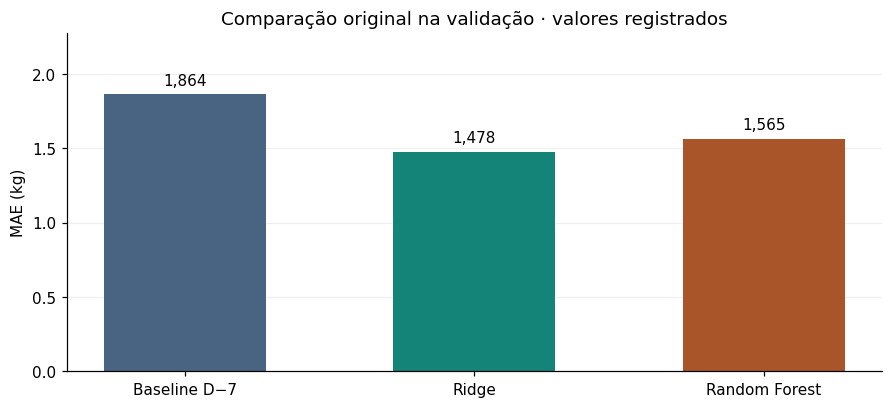

In [6]:
inicial = ler_tabela(
    "comparacao_inicial.md",
    ["Método", "Observações", *COLUNAS_METRICAS.values(), "Variação de MAE"],
)
assert list(inicial["Método"]) == ["Baseline sazonal", "Ridge", "Random Forest"]
assert all(inicial["Observações"].map(numero_ptbr).eq(len(validacao)))
conferir_metricas(baseline_atual, inicial.iloc[0])
display(inicial.assign(Proveniência="Relatório histórico da comparação inicial"))

nomes_iniciais = ["Baseline D−7", "Ridge", "Random Forest"]
mae_inicial = inicial["MAE (kg)"].map(numero_ptbr)
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
barras = ax.bar(nomes_iniciais, mae_inicial, color=[CORES[nome] for nome in nomes_iniciais], width=0.56)
ax.bar_label(barras, labels=[f"{v:.3f}".replace(".", ",") for v in mae_inicial], padding=4)
ax.set(title="Comparação original na validação · valores registrados", ylabel="MAE (kg)",
       ylim=(0, 1.22 * mae_inicial.max()))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()
plt.close(fig)

## 7. Seleção original de hiperparâmetros

A Etapa 3 comparou quatro valores de `alpha` no Ridge e seis combinações de profundidade e tamanho mínimo de folha na Random Forest. O critério principal foi MAE na validação original. O protocolo histórico registrou uma tolerância de 0,005 kg em MAE e RMSE para considerar configurações próximas e favorecer menor capacidade.

O Ridge com `alpha=100.0` obteve o menor MAE da grade, com RMSE superior ao do Ridge inicial. O quadro vem do relatório de seleção. A escolha foi concluída antes do teste final. [Grade e regra originais](../reports/sprint5/selecao_modelo.md)

In [7]:
selecao = ler_tabela(
    "selecao_modelo.md",
    ["Método", "Parâmetros variados", *COLUNAS_METRICAS.values(), "Variação do MAE vs. baseline"],
)
assert selecao["Método"].value_counts().to_dict() == {"Random Forest": 6, "Ridge": 4, "Baseline sazonal": 1}
selecionado = selecao.loc[selecao["Método"].eq("Ridge") &
                         selecao["Parâmetros variados"].str.contains("alpha=100.0", regex=False)]
assert len(selecionado) == 1
assert meta["hiperparametros"]["alpha"] == 100.0
display(selecao.assign(Selecionado=selecao.index.isin(selecionado.index)))
print('Configuração congelada no Ridge v1: alpha=100.0, solver="cholesky".')

,Método,Parâmetros variados,MAE (kg),RMSE (kg),R²,Variação do MAE vs. baseline,Selecionado
0,Baseline sazonal,D−7,"1,863521","2,571085","0,834811","0,00%",False
1,Ridge,`alpha=0.1`,"1,478550","1,987183","0,901321","-20,66%",False
2,Ridge,`alpha=1.0` (Etapa 2),"1,478469","1,987425","0,901297","-20,66%",False
3,Ridge,`alpha=10.0`,"1,477209","1,989931","0,901048","-20,73%",False
4,Ridge,`alpha=100.0`,"1,475061","2,001563","0,899888","-20,85%",True
5,Random Forest,"`max_depth=None`, `min_samples_leaf=1` (Etapa 2)","1,564788","2,166297","0,882731","-16,03%",False
6,Random Forest,"`max_depth=None`, `min_samples_leaf=4`","1,567506","2,160391","0,883369","-15,88%",False
7,Random Forest,"`max_depth=8`, `min_samples_leaf=1`","1,572717","2,171450","0,882172","-15,61%",False
8,Random Forest,"`max_depth=8`, `min_samples_leaf=4`","1,571736","2,165599","0,882806","-15,66%",False
9,Random Forest,"`max_depth=12`, `min_samples_leaf=1`","1,565475","2,161563","0,883243","-15,99%",False


Configuração congelada no Ridge v1: alpha=100.0, solver="cholesky".


## 8. Validação cruzada temporal complementar S5-A

**Análise retrospectiva, realizada após a seleção e a avaliação final do Ridge v1.** Três janelas de origem expansiva avaliam como a configuração congelada se comporta em épocas diferentes do desenvolvimento. Cada fold cria um pipeline Ridge novo, ajustado apenas em seu treino, e compara a previsão com D−7 nos mesmos pares produto/dia.

A célula reproduz o S5-A com a função existente e confronta as métricas com o relatório versionado. Os pipelines dos folds são temporários e o agregado reúne 3.801 previsões de janelas de avaliação disjuntas. [Relatório do S5-A](../reports/sprint5/validacao_cruzada_temporal.md)

In [8]:
cv = evaluate_development(desenvolvimento)
assert cv["hiperparametros"] == {"alpha": 100.0, "solver": "cholesky"}
janelas = pd.DataFrame([{
    "Fold": fold["fold"],
    "Início treino": fold["treino"]["inicio"], "Fim treino": fold["treino"]["fim"],
    "n treino": fold["treino"]["n_observacoes"],
    "Início avaliação": fold["avaliacao"]["inicio"], "Fim avaliação": fold["avaliacao"]["fim"],
    "n avaliação": fold["avaliacao"]["n_observacoes"],
} for fold in cv["folds"]])
display(janelas)

janelas_cv = [(str(fold["fold"]), fold) for fold in cv["folds"]] + [("Agregado", cv["agregado"])]
metodos = (("Baseline D−7", "baseline"), ("Ridge", "ridge"))
linhas_cv = []
registro_cv = ler_tabela(
    "validacao_cruzada_temporal.md",
    ["Fold", "Método", "Observações", *COLUNAS_METRICAS.values(), "Variação do MAE vs. D−7"],
).set_index(["Fold", "Método"])
for janela, resultado in janelas_cv:
    for rotulo, chave in metodos:
        metricas = resultado["metricas"][chave]
        registro = registro_cv.loc[(janela, rotulo)]
        conferir_metricas(metricas, registro)
        assert metricas["n_observacoes"] == numero_ptbr(registro["Observações"])
        linhas_cv.append({
            "Fold": janela, "Método": rotulo, "Observações": metricas["n_observacoes"],
            **metricas_para_tabela(metricas), "Δ MAE vs. D−7 (%)": metricas["variacao_mae_pct"],
        })
tabela_cv = pd.DataFrame(linhas_cv)
display(tabela_cv.round(6))

,Fold,Início treino,Fim treino,n treino,Início avaliação,Fim avaliação,n avaliação
0,1,2025-09-29,2025-12-31,1974,2026-01-01,2026-02-28,1239
1,2,2025-09-29,2026-02-28,3213,2026-03-01,2026-04-30,1281
2,3,2025-09-29,2026-04-30,4494,2026-05-01,2026-06-30,1281


,Fold,Método,Observações,MAE (kg),RMSE (kg),R²,Δ MAE vs. D−7 (%)
0,1,Baseline D−7,1239,2.195004,3.068660,0.736082,0.000000
1,1,Ridge,1239,3.162793,3.634324,0.629816,44.090521
2,2,Baseline D−7,1281,1.878392,2.566593,0.833696,0.000000
3,2,Ridge,1281,1.575935,2.184300,0.879548,-16.101882
4,3,Baseline D−7,1281,1.863521,2.571085,0.834811,0.000000
5,3,Ridge,1281,1.475061,2.001563,0.899888,-20.845449
6,Agregado,Baseline D−7,3801,1.976585,2.741793,0.805048,0.000000
7,Agregado,Ridge,3801,2.059202,2.695108,0.811630,4.179784


### Resultado desfavorável no agregado do S5-A

O Ridge teve MAE menor nos folds 2 e 3. A piora no fold 1 foi suficiente para deixar o **MAE agregado do Ridge em 2,059202 kg**, contra **1,976585 kg** do baseline, uma diferença de **+4,18%**. O RMSE agregado do Ridge foi menor. A divergência é compatível com as métricas ponderarem erros de maneiras diferentes.

O gráfico usa as métricas reproduzidas. A tabela abaixo mostra o MAE agregado por corte. O relatório do S5-A contém também a abertura dos 21 cortes em cada fold.

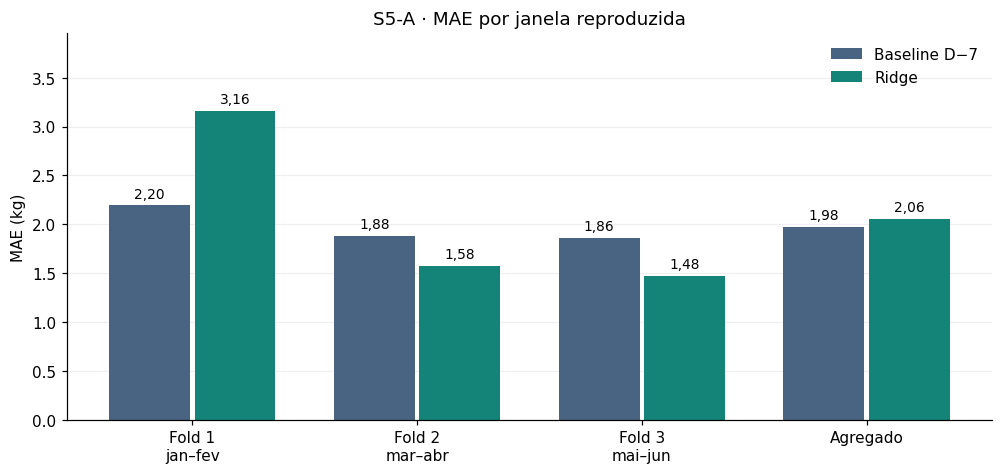

,Corte,Observações,D−7 (kg),Ridge (kg),Diferença Ridge − D−7 (kg)
0,Acém,181,3.859116,3.185484,-0.673632
1,Alcatra,181,2.522431,2.271310,-0.251121
2,Capa de Filé,181,1.421492,1.723922,0.302430
3,Costelão,181,2.674365,2.435821,-0.238544
4,Coxão Duro,181,2.321989,2.016138,-0.305851
5,Coxão Mole,181,2.726133,2.463861,-0.262272
6,Cupim,181,1.366906,1.695305,0.328399
7,Filé Mignon,181,0.954088,1.776464,0.822375
8,Filé Simples,181,1.848453,2.013577,0.165124
9,Filé de Agulha,181,1.810773,2.010818,0.200045


In [9]:
posicoes = np.arange(len(janelas_cv))
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
for deslocamento, (rotulo, _) in zip((-0.19, 0.19), metodos):
    valores = tabela_cv.loc[tabela_cv["Método"].eq(rotulo), "MAE (kg)"].to_numpy()
    barras = ax.bar(posicoes + deslocamento, valores, width=0.36, label=rotulo, color=CORES[rotulo])
    ax.bar_label(barras, labels=[f"{v:.2f}".replace(".", ",") for v in valores], padding=3, fontsize=9)
ax.set_xticks(posicoes, ["Fold 1\njan–fev", "Fold 2\nmar–abr", "Fold 3\nmai–jun", "Agregado"])
ax.set(title="S5-A · MAE por janela reproduzida", ylabel="MAE (kg)",
       ylim=(0, 1.25 * tabela_cv["MAE (kg)"].max()))
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()
plt.close(fig)

display(pd.DataFrame([{
    "Corte": linha["corte"], "Observações": linha["n_observacoes"],
    "D−7 (kg)": linha["mae_kg"]["baseline"], "Ridge (kg)": linha["mae_kg"]["ridge"],
    "Diferença Ridge − D−7 (kg)": linha["mae_kg"]["ridge"] - linha["mae_kg"]["baseline"],
} for linha in cv["agregado"]["por_corte"]]).round(6))

## 9. Teste final do Ridge v1 — resultados registrados

A avaliação histórica ajustou o Ridge congelado com treino e validação até **30/06/2026** e avaliou **01/07 a 31/08/2026**. O MAE do Ridge foi **1,475517 kg**, frente a **1,860814 kg** do baseline, uma redução de **20,7058%**. Essa janela, esse modelo ajustado e essa população diferem do agregado da validação cruzada.

A tabela é lida de `iacarne_ridge_v1.metadata.json` e reconciliada com o relatório final. A conferência de serialização é também um registro histórico. O caderno preserva o teste final sem repetir previsões, ajuste ou cálculo de métricas nesse período. [Avaliação final publicada](../reports/sprint5/avaliacao_final.md)

In [10]:
registro_final = ler_tabela(
    "avaliacao_final.md",
    ["Método", "Observações", *COLUNAS_METRICAS.values(), "Inválidas", "Não finitas", "Negativas"],
).set_index("Método")
linhas_finais = []
for rotulo, chave in metodos:
    metricas = meta["metricas_finais"][chave]
    invalidez = meta["previsoes_invalidas"][chave]
    conferir_metricas(metricas, registro_final.loc[rotulo])
    assert metricas["n_observacoes"] == contagens["teste"] == numero_ptbr(registro_final.loc[rotulo, "Observações"])
    assert invalidez["invalidas"] == numero_ptbr(registro_final.loc[rotulo, "Inválidas"])
    linhas_finais.append({
        "Método": rotulo, "Observações": metricas["n_observacoes"],
        **metricas_para_tabela(metricas), "Inválidas": invalidez["invalidas"],
        "Δ MAE vs. D−7 (%)": metricas["variacao_mae_pct"],
    })
display(pd.DataFrame(linhas_finais).round(6))
reducao_registrada = -meta["metricas_finais"]["ridge"]["variacao_mae_pct"]
print(f"Redução registrada no teste: {reducao_registrada:.4f}%".replace(".", ","))
verificacao = meta["verificacao_serializacao"]
display(pd.DataFrame([{
    "Versão do artefato": meta["versao_artefato"],
    "Data de corte do ajuste": meta["data_corte_treino"],
    "Previsões comparadas na serialização": verificacao["previsoes_comparadas"],
    "Maior diferença registrada (kg)": verificacao["maior_diferenca_absoluta_kg"],
}]))

,Método,Observações,MAE (kg),RMSE (kg),R²,Inválidas,Δ MAE vs. D−7 (%)
0,Baseline D−7,1302,1.860814,2.510438,0.847855,0,0.000000
1,Ridge,1302,1.475517,1.993045,0.904106,0,-20.705821


Redução registrada no teste: 20,7058%


,Versão do artefato,Data de corte do ajuste,Previsões comparadas na serialização,Maior diferença registrada (kg)
0,1.0.0,2026-06-30,1302,0.0


### Erro por corte no teste final registrado

Os pares de pontos mostram o MAE do Ridge v1 e do baseline para os 21 cortes. Cada par corresponde às mesmas 62 observações do respectivo corte. O gráfico usa exclusivamente os valores registrados nos metadados.

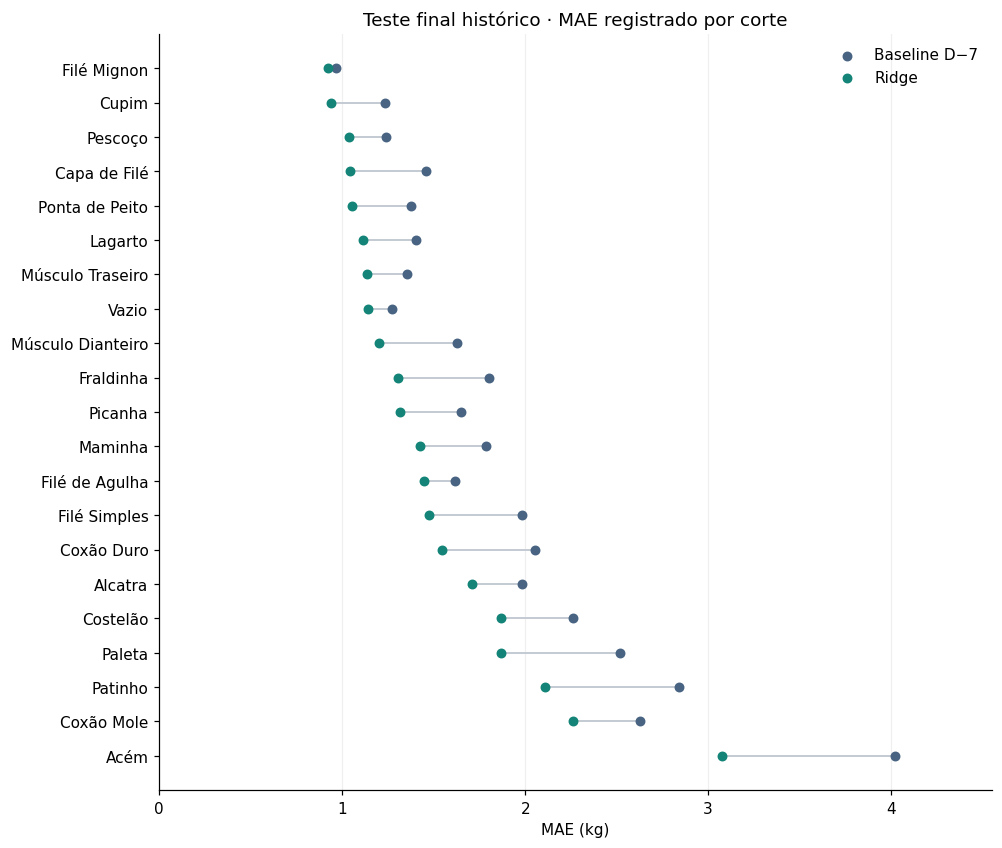

In [11]:
cortes_finais = pd.DataFrame([{
    "Corte": linha["corte"], "Observações": linha["n_observacoes"],
    "Baseline D−7": linha["mae_kg"]["baseline"], "Ridge": linha["mae_kg"]["ridge"],
} for linha in meta["mae_por_corte"]]).sort_values("Ridge")
assert len(cortes_finais) == 21 and cortes_finais["Observações"].eq(62).all()

fig, ax = plt.subplots(figsize=(9, 7.6), layout="constrained")
posicoes = np.arange(len(cortes_finais))
ax.hlines(posicoes, cortes_finais["Ridge"], cortes_finais["Baseline D−7"], color="#C5CBD2", linewidth=1.3)
for rotulo, _ in metodos:
    ax.scatter(cortes_finais[rotulo], posicoes, color=CORES[rotulo], label=rotulo, s=30, zorder=3)
ax.set_yticks(posicoes, cortes_finais["Corte"])
ax.invert_yaxis()
ax.set(title="Teste final histórico · MAE registrado por corte", xlabel="MAE (kg)", xlim=(0, 4.55))
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="upper right", frameon=False)
plt.show()
plt.close(fig)

## 10. Discussão crítica e próximos passos

O teste final registrado favorece o Ridge v1 em MAE. A validação cruzada complementar mostra que essa vantagem não ocorreu em todas as janelas. O fold 1 avalia a virada do ano com um treino mais curto. Como a época avaliada e o tamanho do treino mudam juntos, a comparação não isola a causa da piora. O S5-A complementa a evidência e não substitui a decisão original.

A base é sintética e a EDA anterior já incluiu o período posteriormente reservado ao teste. Os erros são descritivos e dependem dos padrões da simulação, do catálogo fixo e do protocolo diário com históricos já observados. O alvo mede vendas registradas, que podem ser limitadas por estoque. Esses resultados não demonstram redução de perdas ou rupturas, desempenho em uma operação real ou aceite por usuários.

Em checkpoints próprios, a documentação pode consolidar essas evidências. Uma futura avaliação operacional deve usar dados autorizados, unidade compatível, registros disponíveis antes da previsão e critérios definidos com a comunidade parceira. A inferência do Ridge v1 requer os atributos tabulares prontos, inclusive lags calculados com observações anteriores a D.

## Conferência final do caderno

A última célula repete a verificação dos bytes da matriz e do Ridge v1. A execução é considerada íntegra quando os dois hashes são iguais aos do início e aos valores registrados.

In [12]:
hashes_depois = {path: sha256(path.read_bytes()).hexdigest() for path in HASHES_ESPERADOS}
assert hashes_depois == hashes_antes == HASHES_ESPERADOS
for path, digest in hashes_depois.items():
    print(f"{path.as_posix()}\n  SHA-256 {digest}")
print("Matriz e Ridge v1 conferidos antes e depois da execução.")

data/modeling/iacarne_modelagem.csv
  SHA-256 1a6b482dcca3497ed605a821ae13cdd46404186c5d9b94716f8cb2e8f0131772
artifacts/models/iacarne_ridge_v1.joblib
  SHA-256 67b32644862f2b3fcfb3b83b30e3f1498cbd7f7b46e3356ac9dacff86d7bc73f
Matriz e Ridge v1 conferidos antes e depois da execução.
